# DSA 504 — Practical Midterm Exam
## Class 15, Monday, October 26

**Time allowed:** 60 minutes
**Worth:** 15% of your final grade

---

### Rules

- This is an **individual** exam. Do not collaborate or communicate with classmates during the exam.
- **AI tools are not permitted during this exam** (no ChatGPT, Claude, Copilot, Gemini, etc.) — this is a closed-AI assessment, per the course AI-use policy.
- You **may** use: your own past homework/notebooks, the official pandas documentation, and the official SQL/SQLite documentation.
- Work entirely within this notebook. Do not delete or reorder cells.
- You do not need internet access for this exam — no API calls are required.

### Files you need (should already be in the same folder as this notebook)
- `coffee_sales.csv` — the dataset for this exam (you have not seen this file before)
- `coffee_sales.db` — a SQLite database containing the same data, for the SQL section

### Submission
Upload this completed notebook to the Midterm Exam assignment on Brightspace before time is called. No other submission method is required for this exam.

### Grading breakdown
| Section | Weight |
|---|---|
| 1 — Import & Inspect | 15% |
| 2 — Clean | 25% |
| 3 — Query (SQL + pandas) | 25% |
| 4 — Summarize & Visualize | 15% |
| 5 — Explain | 20% |

Partial credit is given throughout — code that runs with a small error earns most of the available credit, not zero. Budget your time using the weights above as a rough guide.


In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
print("Environment OK")


Environment OK


---
## Section 1 — Import & Inspect (15%)

**1a.** Load `coffee_sales.csv` into a variable called `sales`. Print its shape and the data type of each column.


In [ ]:
# 1a — your code here
sales = pd.read_csv("coffee_sales.csv") #Change the file name to a sales one
print(type(sales))
print(sales.shape)
print(sales.columns)
print(sales.dtypes)
print(f"Loaded {len(sales)} rows")

<class 'pandas.DataFrame'>
(1833, 5)
Index(['date', 'location', 'category', 'units_sold', 'revenue'], dtype='str')
date              str
location          str
category          str
units_sold    float64
revenue       float64
dtype: object
Loaded 1833 rows


**1b.** Print how many missing values exist in each column.


In [3]:
# 1b — your code here
print(sales.isna().sum())


date           0
location       0
category       0
units_sold    28
revenue       27
dtype: int64


**1c.** Print the sorted list of unique values in the `category` column, and how many distinct values there are.


In [ ]:
# 1c — your code here
print(sales["category"].unique()) 



<StringArray>
[    'Past ry',       'latte', 'merchandise',         'Tea',      'Pastry',
         'tea',      'pastry',       'Latte', 'Merchandise',    'ESPRESSO',
    'Espresso',    'espresso']
Length: 12, dtype: str


**1d.** Print how many exact duplicate rows exist in the dataset.


In [24]:
# 1d — your code here
# .duplicated() rows that are exact repeats of an earlier row
print(sales.duplicated().sum())
# Looking at the actual duplicate rows
dupes = sales[sales.duplicated(keep=False)]   # keep=False shows ALL copies, not just the extras
# .any() tells you if ANY value in a column is missing (True/False, not a count)
print(sales.isna().any())
print(len(dupes))
dupes.sort_values(list(sales.columns)).head(5)


18
date                 False
location             False
category             False
units_sold            True
revenue               True
units_sold_filled    False
dtype: bool
36


,date,location,category,units_sold,revenue,units_sold_filled
70,2026-01-02,Downtown,Pastry,NaN,186.24,40.0
1807,2026-01-02,Downtown,Pastry,NaN,186.24,40.0
151,2026-01-12,Downtown,merchandise,8.0,151.28,8.0
1384,2026-01-12,Downtown,merchandise,8.0,151.28,8.0
859,2026-01-16,Riverside,pastry,38.0,148.58,38.0


---
## Section 2 — Clean (25%)

**2a.** Fill missing `units_sold` and `revenue` values using an approach you think is reasonable (for example, the column median). In a brief comment, state which approach you chose and why.


In [6]:
# 2a — your code here
# Load the CSV file into the sales variable
sales = pd.read_csv("coffee_sales.csv")

# Calculate counts and percentages of missing values
missing_counts = sales[["units_sold", "revenue"]].isna().sum()
missing_pcts = (sales[["units_sold", "revenue"]].isna().mean()) * 100

print(f"units_sold missing: {missing_counts['units_sold']} ({missing_pcts['units_sold']:.2f}%)")
print(f"revenue missing: {missing_counts['revenue']} ({missing_pcts['revenue']:.2f}%)")
# Fill missing units_sold with median
median_units = sales["units_sold"].median()
sales["units_sold_filled"] = sales["units_sold"].fillna(median_units)

# Filling with the column's median -- often more robust than mean if outliers exist
median_units = sales["units_sold"].median()
filled_median = sales["units_sold"].fillna(median_units)
print(f"Column median used for filling: {median_units}")

units_sold missing: 28 (1.53%)
revenue missing: 27 (1.47%)
Column median used for filling: 40.0


**2b.** Remove exact duplicate rows. Print the row count before and after.


In [21]:
# 2b — your code here
rows_before = len(sales) #remove the duplicates for this rows
sales_deduped = sales.drop_duplicates()
rows_after = len(sales_deduped)

print(f"Rows before: {rows_before}")
print(f"Rows after: {rows_after}")
print(f"Duplicates removed: {rows_before - rows_after}")


Rows before: 1833
Rows after: 1815
Duplicates removed: 18


**2c.** Clean the `category` column into a new column called `category_clean`. It should end up with **exactly 5** distinct values. Print the sorted unique values of `category_clean` to confirm.


In [20]:
# 2c — your code here
# Clean the category column for this part
sales_clean = sales_deduped.copy()

sales_clean["category_clean"] = (
    sales_clean["category"]
    .str.lower()
    .str.strip()
    .str.replace("past ry", "pastry", regex=False)
    .str.capitalize()
)

unique_categories = sorted(sales_clean["category_clean"].unique()) # Confirm sorted unique values of this example
print("Unique values in category_clean:", unique_categories)
print(f"Total distinct values: {sales_clean['category_clean'].nunique()}")


Unique values in category_clean: ['Espresso', 'Latte', 'Merchandise', 'Pastry', 'Tea']
Total distinct values: 5


**2d.** Convert the `date` column to a proper datetime type. Confirm the new data type.


In [19]:
# 2d — your code here
# Convert the date column to datetime type
sales_clean["date"] = pd.to_datetime(sales_clean["date"])
print("Data type of the date column:", sales_clean["date"].dtype) # Confirm the new data type


Data type of the date column: datetime64[us]


---
## Section 3 — Query (SQL + pandas) (25%)

**3a.** Connect to `coffee_sales.db` (it contains one table, `sales`, with the same raw/uncleaned data as the CSV). Write a SQL query that returns the **total revenue per location**, sorted from highest to lowest. Run it with `pd.read_sql_query()`.


In [13]:
# 3a — your code here
conn = sqlite3.connect("coffee_sales.db")

sql_query = """
SELECT location, SUM(revenue) AS total_revenue
FROM sales
GROUP BY location
ORDER BY total_revenue DESC;
"""

sql_results = pd.read_sql_query(sql_query, conn)
conn.close()

print(sql_results)


    location  total_revenue
0   Lakeside       85355.30
1   Downtown       84431.16
2  Hillcrest       84347.11
3  Riverside       81334.44


**3b.** Now answer the same question — total revenue per location, highest to lowest — using **pandas** instead of SQL, starting from your cleaned `sales` DataFrame from Section 2. Do the two approaches agree in which location is highest? (They may not match exactly in the numbers, since one uses raw data and one uses your cleaned data — that's expected. Note this in a comment.)


In [22]:
# 3b — your code here
pandas_results = (
    sales_clean.groupby("location")["revenue"]
    .sum()
    .reset_index()
    .sort_values(by="revenue", ascending=False)
)

print(pandas_results)

# Lakeside is the highest revenue location. The numeric totals are diferent because SQL queries the database 


    location   revenue
2   Lakeside  84481.63
1  Hillcrest  83972.45
0   Downtown  83792.87
3  Riverside  80664.64


---
## Section 4 — Summarize & Visualize (15%)

**4a.** Using your cleaned data, compute the average `revenue` per `category_clean`.


In [23]:
# 4a — your code here
avg_rev_by_cat = (
    sales_clean.groupby("category_clean")["revenue"]
    .mean()
    .reset_index()
    .sort_values(by="revenue", ascending=False)
)

print(avg_rev_by_cat)


  category_clean     revenue
1          Latte  352.740507
0       Espresso  190.525938
3         Pastry  166.850826
2    Merchandise  144.780351
4            Tea   79.755310


**4b.** Create one chart (matplotlib or seaborn, your choice) that shows this result visually. Include a title and axis labels.


C:\Users\nvasquez\AppData\Local\Temp\ipykernel_15020\2273631036.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


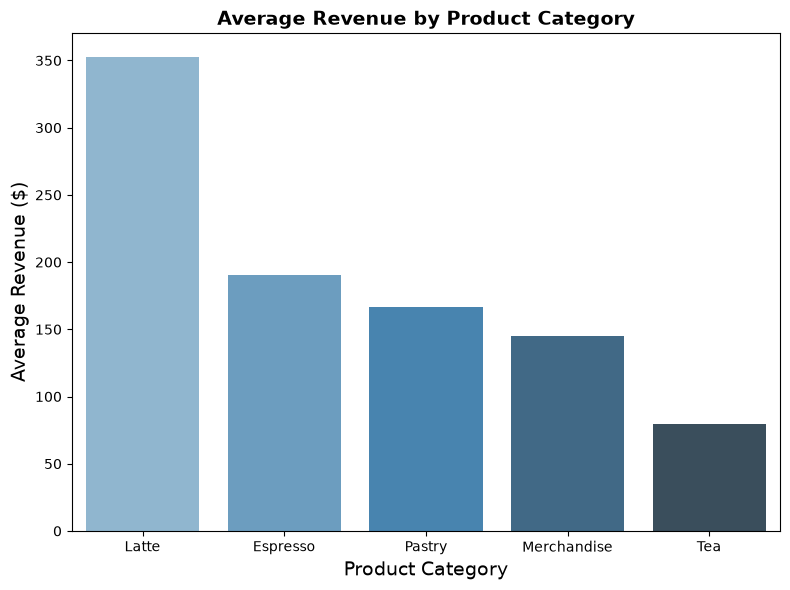

In [27]:
# 4b — your code here
plt.figure(figsize=(8, 6))
sns.barplot(
    data=avg_rev_by_cat, 
    x="category_clean", 
    y="revenue", 
    palette="Blues_d"
)

plt.title("Average Revenue by Product Category", fontsize=14, fontweight="bold")
plt.xlabel("Product Category", fontsize=14)
plt.ylabel("Average Revenue ($)", fontsize=14)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


---
## Section 5 — Explain (20%)

Answer each question in 1–3 sentences, directly in the markdown cell provided.


**5a.** Why did you choose the missing-value strategy you used in 2a? What would be a downside of that choice?

I chose the column median to fill missing values because it is better against outliers compared to the mean. The downside of this is that imputing is the dataset.


**5b.** Looking at your Section 3 results: why might the SQL query and the pandas result not match exactly, even though they're answering the same question?

They do not match because SQL database table containing exact duplicates and missing values, in the other hand pandas operated on our cleaned DataFrame the missing values.


**5c.** Suppose a manager wanted to use your Section 4 chart to decide which category to promote more heavily next quarter. What is one reason they should be cautious about relying on this chart alone?

The chart only shows average revenue, not total or overall sales. A category with a high average revenue might be better for low sales compared to a bigger volume item.
